# Anatomy of an AI Agent

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/drive/1UyDAnjQZ-TbFGpXoHYcc1ff3Pc0apFE6?usp=sharing)

**The goal, concretely.** Maya is flying to Tokyo in 3 days for work. She wants one
assistant that can: check the real multi-day forecast for her dates, turn that into a
day-by-day itinerary, tell her what to pack, keep her daily budget straight in yen, and
sanity-check a real photo of what she's packed or what Tokyo looks like right now. Every
term below exists because Maya's assistant needs it, not as an isolated toy demo. By the
time you reach the capstone at the end, all of it comes together to actually solve her
trip.

**How this notebook works.** Every term below gets built from scratch in plain Python,
using a free Gemma 4 endpoint on [OpenRouter](https://openrouter.ai). No agent
frameworks anywhere. We also wire up real tools along the way (a real weather-forecast
API, a real currency-conversion API, real image understanding), so by the end this is not
a pile of toy examples. It is one working travel-assistant agent that checks real weather,
reasons about it, and gives real packing and budget advice.

By the end you will have hand-built:

`Model` → `Scaffolding` → `Harness` → `Agent` → `Context Engineering` → `Policy` → `Tool Use` → `Skills` → `Sub-agents` → `Multimodal Input` → `Capstone`

Once these are transparent, frameworks like CrewAI or LangGraph stop looking like magic.
They are doing exactly what we do here, just with more configuration surface and
production concerns (retries, observability, parallelism) handled for you.

> This is a *learning* implementation, not a production one. No retries, no streaming, no
> proper async. Every line is written to be read, not to be robust.

## 0. Setup

This notebook runs against [OpenRouter](https://openrouter.ai)'s free Gemma 4
endpoint.

We use **Gemma 4** (`google/gemma-4-26b-a4b-it:free`), Google DeepMind's latest
open-weight family. It's a better fit for this workshop than a generic small model
because it was built with agentic use in mind. More on that below. A second free variant,
`google/gemma-4-31b-it:free`, is also available on OpenRouter if you want to compare.

You'll need a free OpenRouter API key.
1. Get one at [openrouter.ai/keys](https://openrouter.ai/keys).
2. Create a file named `.env` in this project folder with one line:
   `OPENROUTER_API_KEY=sk-or-...`
3. The setup cell below loads it from there. Never commit `.env` to version control.

The only credential this whole notebook needs is the OpenRouter key. All three followings are free and need no account or key.

* The weather tool later in the notebook calls a real, free forecast API (Open-Meteo).
* The currency tool calls a real, free exchange-rate API (Frankfurter).
* And the multimodal section pulls a real photo from Wikimedia Commons. 

> **Note.** OpenRouter's free tier is rate-limited: 20 requests a minute per key, and the
> free Gemma 4 endpoint is also limited upstream by its single provider. If a cell errors
> with a 429, wait a moment and re-run it. If it keeps happening, add `MODEL=...` to `.env`
> with one of the alternatives listed in the setup cell.

In [1]:
# Dependencies (openai, python-dotenv) are already installed if you ran `uv sync`.
# Running somewhere else, like Colab? This installs only what's missing.
import importlib.util

missing = [pkg for pkg, mod in [("openai", "openai"), ("python-dotenv", "dotenv")]
           if importlib.util.find_spec(mod) is None]
if missing:
    %pip install -q {" ".join(missing)}


In [2]:
from openai import OpenAI, RateLimitError
import json
import os
from dotenv import load_dotenv

# Reads OPENROUTER_API_KEY from a local .env file (see section 0 above),
# or from a Colab secret of the same name when running on Colab.
load_dotenv()

api_key = os.environ.get("OPENROUTER_API_KEY")
if not api_key:
    try:
        from google.colab import userdata
        api_key = userdata.get("OPENROUTER_API_KEY")
    except Exception:
        pass
if not api_key:
    raise RuntimeError(
        "OPENROUTER_API_KEY not found. Create a .env file in this project folder "
        "with OPENROUTER_API_KEY=sk-or-... (get a free key at openrouter.ai/keys), "
        "or add it as a Colab secret."
    )

# Initialize the OpenAI client with the OpenRouter endpoint
client = OpenAI(
    base_url="https://openrouter.ai/api/v1",
    api_key=api_key,
)

# Define the model to use. Set MODEL in .env to switch without editing code:
#   google/gemma-4-26b-a4b-it         same Gemma 4, paid (this whole notebook costs well under 1 cent)
#   nvidia/nemotron-3.5-super-vl:free  free fallback with the same four capabilities
MODEL = os.environ.get("MODEL", "google/gemma-4-26b-a4b-it:free")

# Sanity check
try:
    resp = client.chat.completions.create(
        model=MODEL,
        messages=[{"role": "user", "content": "Hello!"}],
    )
    print(f"[{MODEL}]", resp.choices[0].message.content)
except RateLimitError:
    print(
        f"{MODEL} is rate-limited right now (429). The free Gemma 4 endpoint has one "
        "upstream provider and is often busy. Wait and re-run, or set MODEL to one of "
        "the alternatives above."
    )


[google/gemma-4-26b-a4b-it] Hello! How can I help you today?


### About this model

A harness is only as reliable as the model's ability to do the things the harness asks
of it. Four things about Gemma 4 matter for that, and each one comes back later in this
notebook.

- A harness that hands out `tools` is betting the model will describe calls correctly and
  consistently. Gemma 4 was trained specifically for agentic workflows, not retrofitted
  for tool use after the fact, so its `tool_calls` should be more reliable than a
  general-purpose small model's.

- Scaffolding needs somewhere to put instructions that isn't the user's own message.
  Earlier Gemma generations had no first-class `system` role in their chat template, so
  people worked around it by folding instructions into the first user turn. Gemma 4
  supports `system` directly, which is the exact mechanism this notebook leans on
  throughout.

- Some questions are worth the extra latency of step-by-step reasoning, and some aren't.
  Gemma 4 lets a harness make that call per request. Under the hood the switch is a
  control token at the start of the system prompt; OpenRouter's `reasoning` API parameter
  adds it for you, so there's no different model file and nothing to type into the prompt.

- Some of what Maya's assistant needs later isn't text at all — a photo of what Tokyo
  looks like right now. Gemma 4 takes an image as part of its input, not just text, so
  the same model handles that case too.

## 1. Model

The model is the LLM itself. It takes text in and produces text out, nothing more.

* On its own, a model has no memory between calls and no loop that keeps it running.
* It can express the *intent* to call a tool, but it can't actually run anything.
* It answers one prompt and stops.

Let's prove each part of that claim, one cell at a time.

In [3]:
# One prompt in, one response out.
response = client.chat.completions.create(
    model=MODEL,
    messages=[{"role": "user", "content": "What's 17 * 24?"}],
)
print(response.choices[0].message.content)

17 * 24 = **408**


### No memory between calls

Every `client.chat.completions.create(...)` call is stateless. Unless *we* pass the
previous conversation back in, the model has no idea what just happened.

In [4]:
# A fresh call, no history included
response = client.chat.completions.create(
    model=MODEL,
    messages=[{"role": "user", "content": "What number did I just ask you to compute?"}],
)
print(response.choices[0].message.content)

# The model has no idea, because we never sent the previous turn back to it.
# Anything that feels like "memory" in a chatbot is something we build, not something
# the model has natively.

You haven't asked me to compute any numbers yet in this conversation. I am ready when you are!


### It can express intent to call a tool, but can't act on it

We can offer the model a `tools` schema. It can *decide* to call one and describe the
call, but nothing actually runs unless something else, the harness, executes it.

In [5]:
# Tools schema
tools = [
    {
        "type": "function",
        "function": {
            "name": "get_weather",
            "description": "Get the current weather for a city.",
            "parameters": {
                "type": "object",
                "properties": {"city": {"type": "string", "description": "City name"}},
                "required": ["city"],
            },
        },
    }
]

# Model call
response = client.chat.completions.create(
    model=MODEL,
    messages=[{"role": "user", "content": "What's the weather in Paris right now?"}],
    tools=tools,
)

# Message and tool calls
msg = response.choices[0].message
print("Text content:", msg.content)
print("Tool calls requested:", msg.tool_calls)

# The model returns a *request* to call get_weather(city="Paris").
# It did not and cannot check the weather itself. It has no hands.
# If we stop here, the conversation just... stops. Nothing happened.

Text content: None
Tool calls requested: [ChatCompletionMessageFunctionToolCall(id='call-da54c028-0c58-43a3-abd3-8d8ab52c50fa', function=Function(arguments='{"city":"Paris"}', name='get_weather'), type='function', index=0)]


## 2. Scaffolding

Scaffolding is the behavior-defining layer around the model. It's the system prompt, the
tool descriptions, how the model's responses get parsed, and what it remembers across
steps. It shapes how the model sees the world and how it can act in it.

Scaffolding is **data and structure**, not a loop. Let's define ours with real Python
functions (a live weather-forecast API and a live currency-conversion API, both free and
keyless), their schemas so the model knows they exist, and a system prompt. Nothing here
executes anything yet. We're just building what the model will be shown.

In [6]:
# --- Real Python functions the model will be able to "use" ---
import urllib.request
import urllib.parse

# WMO weather codes -> short human description. Open-Meteo returns a numeric code;
# this table is just how we turn that number into words for the model.
WMO_WEATHER_CODES = {
    0: "clear sky", 1: "mostly clear", 2: "partly cloudy", 3: "overcast",
    45: "fog", 48: "depositing rime fog",
    51: "light drizzle", 53: "drizzle", 55: "dense drizzle",
    56: "light freezing drizzle", 57: "dense freezing drizzle",
    61: "light rain", 63: "rain", 65: "heavy rain",
    66: "light freezing rain", 67: "heavy freezing rain",
    71: "light snow", 73: "snow", 75: "heavy snow", 77: "snow grains",
    80: "light showers", 81: "showers", 82: "violent showers",
    85: "light snow showers", 86: "heavy snow showers",
    95: "thunderstorm", 96: "thunderstorm with light hail",
    97: "heavy thunderstorm", 99: "thunderstorm with heavy hail",
}


def get_weather(city: str, forecast_days: int = 1) -> str:
    """Real tool. Geocodes the city, then fetches current conditions from Open-Meteo,
    free and keyless. When forecast_days > 1, also returns that many days of daily
    highs/lows/conditions, which is what lets a multi-day itinerary actually be
    weather-aware instead of only knowing what it's like right now."""
    try:
        geocode_url = "https://geocoding-api.open-meteo.com/v1/search?" + urllib.parse.urlencode(
            {"name": city, "count": 1}
        )
        with urllib.request.urlopen(geocode_url, timeout=10) as r:
            geocode_result = json.loads(r.read())

        if not geocode_result.get("results"):
            return f"No weather data for {city}"
        place = geocode_result["results"][0]

        forecast_url = "https://api.open-meteo.com/v1/forecast?" + urllib.parse.urlencode(
            {
                "latitude": place["latitude"],
                "longitude": place["longitude"],
                "current": "temperature_2m,weather_code",
                "daily": "temperature_2m_max,temperature_2m_min,weather_code",
                "forecast_days": forecast_days,
                "timezone": "auto",
            }
        )
        with urllib.request.urlopen(forecast_url, timeout=10) as r:
            forecast_result = json.loads(r.read())

        current = forecast_result["current"]
        condition = WMO_WEATHER_CODES.get(current["weather_code"], "unknown conditions")
        summary = f"Now: {current['temperature_2m']}C, {condition}."

        if forecast_days > 1:
            daily = forecast_result["daily"]
            day_lines = []
            for i, date in enumerate(daily["time"]):
                day_condition = WMO_WEATHER_CODES.get(daily["weather_code"][i], "unknown conditions")
                day_lines.append(
                    f"{date}: high {daily['temperature_2m_max'][i]}C / "
                    f"low {daily['temperature_2m_min'][i]}C, {day_condition}"
                )
            summary += " Forecast: " + "; ".join(day_lines) + "."

        return summary
    except Exception as e:
        return f"Could not fetch weather for {city}: {e}"


def convert_currency(amount: float, from_currency: str, to_currency: str) -> str:
    """Real tool. Converts an amount between currencies using Frankfurter's free,
    keyless exchange-rate API (ECB reference rates). No internal try/except on
    purpose: if the currency code is bad, the exception should propagate up to
    whoever is calling this, not get swallowed here."""
    headers = {"User-Agent": "anatomy-of-ai-agent/1.0 (workshop demo)"}
    url = "https://api.frankfurter.dev/v1/latest?" + urllib.parse.urlencode(
        {"amount": amount, "from": from_currency.upper(), "to": to_currency.upper()}
    )
    req = urllib.request.Request(url, headers=headers)
    with urllib.request.urlopen(req, timeout=10) as r:
        result = json.loads(r.read())
    converted = result["rates"][to_currency.upper()]
    return f"{amount} {from_currency.upper()} = {converted} {to_currency.upper()}"


# A dispatch table: tool name (string, as the model will refer to it) -> actual function
AVAILABLE_TOOLS = {
    "get_weather": get_weather,
    "convert_currency": convert_currency,
}

In [7]:
# --- Tool schemas: how we DESCRIBE those functions to the model ---
# This is the model's only view into what these tools do. If the description is bad,
# the model will misuse the tool. This is a real, common failure mode.

tools_schema = [
    {
        "type": "function",
        "function": {
            "name": "get_weather",
            "description": (
                "Get current weather for a city. Pass forecast_days > 1 to also get "
                "that many days of daily forecast, e.g. forecast_days=3 for a 3-day trip."
            ),
            "parameters": {
                "type": "object",
                "properties": {
                    "city": {"type": "string", "description": "City name, e.g. 'Tokyo'"},
                    "forecast_days": {
                        "type": "integer",
                        "description": "How many days of daily forecast to include (default 1 = current only)",
                    },
                },
                "required": ["city"],
            },
        },
    },
    {
        "type": "function",
        "function": {
            "name": "convert_currency",
            "description": "Convert an amount from one currency to another using live exchange rates.",
            "parameters": {
                "type": "object",
                "properties": {
                    "amount": {"type": "number", "description": "Amount to convert"},
                    "from_currency": {"type": "string", "description": "3-letter source currency code, e.g. 'USD'"},
                    "to_currency": {"type": "string", "description": "3-letter target currency code, e.g. 'JPY'"},
                },
                "required": ["amount", "from_currency", "to_currency"],
            },
        },
    },
]

# System prompt
SYSTEM_PROMPT = (
    "You are a helpful travel assistant with access to tools. "
    "Use a tool whenever it would give a more accurate answer than guessing. "
    "Keep answers short."
)

# The scaffold, made concrete: system prompt + tool schemas + a running message list.
messages = [{"role": "system", "content": SYSTEM_PROMPT}]

print("Scaffolding assembled.")
print("- system prompt:", SYSTEM_PROMPT)
print("- tools available:", [t["function"]["name"] for t in tools_schema])
print("- message history so far:", messages)

Scaffolding assembled.
- system prompt: You are a helpful travel assistant with access to tools. Use a tool whenever it would give a more accurate answer than guessing. Keep answers short.
- tools available: ['get_weather', 'convert_currency']
- message history so far: [{'role': 'system', 'content': 'You are a helpful travel assistant with access to tools. Use a tool whenever it would give a more accurate answer than guessing. Keep answers short.'}]


## 3. Harness

Scaffolding was inert data. The harness is the execution layer that actually *does*
something with it. It calls the model, notices `tool_calls`, executes the real Python
functions, feeds the results back, and decides when the task is done.

We'll do this manually first, one step at a time, so every moving part is visible. Then
we'll wrap it into a loop.

In [8]:
# --- One harness step, done by hand ---

messages.append({
    "role": "user",
    "content": "What's the weather in Tokyo, and separately, convert $500 to Japanese yen?",
})

response = client.chat.completions.create(model=MODEL, messages=messages, tools=tools_schema)
msg = response.choices[0].message

print("Model wants to call:", [tc.function.name for tc in (msg.tool_calls or [])])
for tc in (msg.tool_calls or []):
    print(" -", tc.function.name, tc.function.arguments)

Model wants to call: ['get_weather', 'convert_currency']
 - get_weather {"city": "Tokyo"}
 - convert_currency {"amount": 500, "from_currency": "USD", "to_currency": "JPY"}


In [9]:
# The harness now does what the model can't: actually run the tools.

# 1. Record the model's turn (including its tool call requests) in history
messages.append(msg.model_dump(exclude_unset=True))

# 2. Execute each requested tool call for real
for tool_call in msg.tool_calls:
    fn_name = tool_call.function.name
    fn_args = json.loads(tool_call.function.arguments)
    result = AVAILABLE_TOOLS[fn_name](**fn_args)
    print(f"Executed {fn_name}({fn_args}) -> {result}")

    # 3. Feed the result back into the conversation as a 'tool' message
    messages.append({
        "role": "tool",
        "tool_call_id": tool_call.id,
        "name": fn_name,
        "content": str(result),
    })

Executed get_weather({'city': 'Tokyo'}) -> Now: 4.5C, clear sky.
Executed convert_currency({'amount': 500, 'from_currency': 'USD', 'to_currency': 'JPY'}) -> 500 USD = 79322 JPY


In [10]:
# 4. Call the model again. Now it has real tool results to work with
final_response = client.chat.completions.create(model=MODEL, messages=messages, tools=tools_schema)
print(final_response.choices[0].message.content)

# That round-trip (call model, notice tool_calls, execute, feed back, call model again)
# IS the harness. Everything below just wraps this in a loop so it can repeat until
# the model stops asking for tools.

The current weather in Tokyo is 4.5°C with clear skies. Also, $500 is approximately 79,322 JPY.


### Now wrap it into a loop

A real task might need several rounds of tool calls before the model is ready to answer.
The harness keeps looping until the model responds with plain text and no tool_calls.
That's our stopping condition.

In [11]:
def run_harness(messages, tools_schema, available_tools, max_turns=6):
    """The harness: drives the model through a tool-use loop until it produces
    a final text answer, or we hit max_turns (a basic safety guardrail)."""
    for turn in range(max_turns):
        response = client.chat.completions.create(model=MODEL, messages=messages, tools=tools_schema)
        msg = response.choices[0].message
        messages.append(msg.model_dump(exclude_unset=True))

        # Stopping condition: the model answered in plain text, no tool calls requested
        if not msg.tool_calls:
            return messages, msg.content

        # Otherwise: execute every requested tool call, feed results back, loop again
        for tool_call in msg.tool_calls:
            fn_name = tool_call.function.name
            try:
                fn_args = json.loads(tool_call.function.arguments)
                result = available_tools[fn_name](**fn_args)
            except Exception as e:
                result = f"Error: {e}"  # harness-level error handling
            messages.append({
                "role": "tool",
                "tool_call_id": tool_call.id,
                "name": fn_name,
                "content": str(result),
            })

    return messages, "[Stopped: max turns reached without a final answer]"

In [12]:
messages = [
    {"role": "system", "content": SYSTEM_PROMPT},
    {"role": "user", "content": "Get the weather in New York, then tell me if I need an umbrella."},
]

# Run the harness
messages, final_answer = run_harness(messages, tools_schema, AVAILABLE_TOOLS)
print(final_answer)

The current weather in New York is 14.5°C and overcast. Since it's overcast, you might want to keep an umbrella handy just in case, although no immediate rain is reported.


## 4. Agent

`Agent = Model + Harness`

We now have every piece. A **model** (the OpenRouter call), **scaffolding** (system
prompt, tool schemas, message list), and a **harness** (the loop that drives them).
Packaging these into one class gives us an `Agent`.

In [13]:
class Agent:
    def __init__(self, model, system_prompt, tools_schema, available_tools, max_turns=6, reasoning=None):
        self.model = model
        self.tools_schema = tools_schema          # scaffolding: what tools the model sees
        self.available_tools = available_tools    # scaffolding: what actually runs
        self.max_turns = max_turns
        self.reasoning = reasoning                # e.g. {"enabled": True}, passed straight to the API
        self.last_reasoning = None                # most recent reasoning trace, if the API returned one
        self.messages = [{"role": "system", "content": system_prompt}]  # scaffolding: running context

    def run(self, user_input: str) -> str:
        self.messages.append({"role": "user", "content": user_input})

        for _ in range(self.max_turns):
            kwargs = {"model": self.model, "messages": self.messages, "tools": self.tools_schema}
            if self.reasoning:
                # `reasoning` is an OpenRouter field, not an OpenAI one, so it goes in extra_body
                kwargs["extra_body"] = {"reasoning": self.reasoning}
            response = client.chat.completions.create(**kwargs)

            # Check if choices is not empty and message is not None
            if not response.choices or response.choices[0].message is None:
                return "[Stopped: Model returned no message or empty choices]"

            msg = response.choices[0].message
            self.last_reasoning = getattr(msg, "reasoning", None)
            self.messages.append(msg.model_dump(exclude_unset=True))

            if not msg.tool_calls:
                if msg.content:
                    return msg.content
                # No text and no tool calls: not a real answer. Ask once more instead of returning None.
                self.messages.append({"role": "user", "content": "Please give your final answer now."})
                continue

            for tool_call in msg.tool_calls:
                fn_name = tool_call.function.name
                try:
                    fn_args = json.loads(tool_call.function.arguments)
                    result = self.available_tools[fn_name](**fn_args)
                except Exception as e:
                    result = f"Error: {e}"
                self.messages.append({
                    "role": "tool",
                    "tool_call_id": tool_call.id,
                    "name": fn_name,
                    "content": str(result),
                })

        return "[Stopped: max turns reached]"

In [14]:
agent = Agent(
    model=MODEL,
    system_prompt=SYSTEM_PROMPT,
    tools_schema=tools_schema,
    available_tools=AVAILABLE_TOOLS,
)

print(agent.run("What's the weather in Bengaluru?"))

The current weather in Bengaluru is 19.6°C and partly cloudy.


In [15]:
# self.messages persists across calls on the SAME agent instance,
# so within one Agent, later turns DO see earlier ones. Try it:
print(agent.run("What city did I just ask about?"))

You just asked about Bengaluru.


## 5. Context engineering

Short-term memory is what stays in the context window during a single run. Long-term
memory persists across sessions. It's stored externally and retrieved on demand, then
injected back into context when relevant.

We just saw **short-term memory**: `agent.messages` growing within one `Agent` instance.
That memory dies the moment the object does. A **fresh** `Agent` has none of it. Let's
prove that, then build long-term memory as an external store the harness reads from and
writes to.

In [16]:
# A brand-new Agent instance has no idea what we discussed with the old one.
fresh_agent = Agent(MODEL, SYSTEM_PROMPT, tools_schema, AVAILABLE_TOOLS)
print(fresh_agent.run("What city did I just ask about?"))
# It doesn't know. Short-term memory does not survive past the object that held it.

You haven't asked about a city in our current conversation yet. If you have one in mind, feel free to let me know!


In [17]:
# --- Long-term memory: stored externally, retrieved on demand, injected into context ---
import os

MEMORY_FILE = "long_term_memory.json"

def save_memory(fact: str):
    """Save a fact to long-term memory."""
    facts = load_memory()
    facts.append(fact)
    with open(MEMORY_FILE, "w") as f:
        json.dump(facts, f)

def load_memory():
    """Load long-term memory from disk."""
    if os.path.exists(MEMORY_FILE):
        with open(MEMORY_FILE) as f:
            return json.load(f)
    return []

save_memory("The user's favorite city is Tokyo.")
save_memory("The user prefers short, direct answers.")
print(load_memory())

["The user's favorite city is Tokyo.", 'The user prefers short, direct answers.']


In [18]:
# Build a NEW system prompt that injects retrieved long-term memory.
# This is context engineering: deciding what goes into the window at each step.
remembered_facts = load_memory()
system_prompt_with_memory = (
    SYSTEM_PROMPT
    + "\n\nThings you know about this user from past sessions:\n"
    + "\n".join(f"- {fact}" for fact in remembered_facts)
)

another_fresh_agent = Agent(MODEL, system_prompt_with_memory, tools_schema, AVAILABLE_TOOLS)
print(another_fresh_agent.run("What's my favorite city, and what's the weather there?"))

# This agent has zero short-term memory of any prior conversation, and yet it "remembers"
# the user's favorite city because we retrieved it from external storage and injected
# it into context before the run started. That's the whole trick behind long-term memory.

Your favorite city is Tokyo. The current weather there is 4.5°C with a clear sky.


## 6. Policy

A policy is the behavior an agent follows. Part of that behavior is learned in the model
weights, but the rest depends on the surrounding scaffolding and harness. The same model
can behave very differently depending on its prompts, tools, memory, and execution loop.

Same weights (`MODEL`, unchanged), same harness, same tools.
Only the **scaffolding** (system prompt) differs. Watch how differently the resulting
behavior looks on an identical question. The question needs a judgement call, not just a
number, so there's room for the two policies to actually diverge.

In [19]:
# Terse agent with a system prompt that prefers short answers
terse_agent = Agent(
    model=MODEL,
    system_prompt="You are a terse assistant. Answer in 5 words or fewer. No explanations.",
    tools_schema=tools_schema,
    available_tools=AVAILABLE_TOOLS,
)

# Verbose agent with a system prompt that encourages explanations
verbose_agent = Agent(
    model=MODEL,
    system_prompt=(
        "You are a thorough, friendly assistant. Always explain your reasoning "
        "and give context around your answer."
    ),
    tools_schema=tools_schema,
    available_tools=AVAILABLE_TOOLS,
)

question = "Should I bring an umbrella in Paris today?"

print("--- terse_agent ---")
print(terse_agent.run(question))
print()
print("--- verbose_agent ---")
print(verbose_agent.run(question))

# Same model weights underneath both. The only thing that changed is the
# scaffolding. A policy is not just the weights, and a policy is not the same thing
# as an agent either.

--- terse_agent ---


No, it's just overcast.

--- verbose_agent ---


To give you the best advice, I checked the current weather for Paris. 

Right now, it is **8.5°C and overcast**. 

While the report doesn't explicitly mention active rainfall at this exact moment, "overcast" skies often mean a higher chance of rain or damp conditions. Because the weather can be unpredictable when it's cloudy, **I would recommend bringing an umbrella** just to be safe, especially if you plan to be walking around outdoors for a while!


## 6b. Reasoning, another scaffolding lever

Gemma 4 supports a **configurable thinking mode**. At the model level it's switched on by a
control token at the start of the system prompt (`<|think|>` in Gemma 4's chat template).
You don't type that token yourself. OpenRouter exposes the switch as a request parameter,
`reasoning={"enabled": True}` (or an `effort` level), adds the token for you, and returns the
model's step-by-step reasoning in a separate `message.reasoning` field instead of inline in
the answer. Because `reasoning` is an OpenRouter field rather than an OpenAI one, the
`Agent` class sends it through the OpenAI client's `extra_body`.

No weights change, no different model file. It's still scaffolding, exactly like the terse
and verbose prompts above, just set through the API call instead of the prompt text.

We'll compare thinking off vs on for a small multi-step reasoning problem. "Off" is set
explicitly with `{"enabled": False}`: some models and providers think by default, so
leaving the parameter out doesn't guarantee thinking is off.


In [20]:
# Reasoning question to test thinking
reasoning_question = (
    "A train leaves Station A at 60 km/h. Twenty minutes later, a second train leaves "
    "the same station on the same track at 90 km/h. How many minutes after the SECOND "
    "train departs does it catch the first one? Give just the final number of minutes."
)

# No thinking: switched off explicitly, since some models think by default
no_think_agent = Agent(
    model=MODEL,
    system_prompt=SYSTEM_PROMPT,
    tools_schema=[],
    available_tools={},
    reasoning={"enabled": False},
)

# Thinking enabled: the real mechanism is the reasoning API parameter, not prompt text
think_agent = Agent(
    model=MODEL,
    system_prompt=SYSTEM_PROMPT,
    tools_schema=[],
    available_tools={},
    reasoning={"enabled": True},
)

print("--- thinking disabled ---")
print(no_think_agent.run(reasoning_question))
print()
print("--- thinking enabled ---")
print(think_agent.run(reasoning_question))
print()
print("--- no_think_agent trace:", "none" if not no_think_agent.last_reasoning else "present")
print("--- think_agent's reasoning trace (message.reasoning, separate from content) ---")
print(think_agent.last_reasoning)

# The reasoning trace lands in its own field, not inline in the answer. A harness has to
# actively DECIDE whether to show that to the user or hide it. Claude Code, for example,
# renders extended thinking as a distinct, collapsible section rather than inline text.
# That's a harness-level product decision, not something the model dictates.

--- thinking disabled ---


40

--- thinking enabled ---


40

--- no_think_agent trace: none
--- think_agent's reasoning trace (message.reasoning, separate from content) ---
*   Train 1 speed ($v_1$): 60 km/h.
    *   Train 2 speed ($v_2$): 90 km/h.
    *   Time delay ($t_{delay}$): 20 minutes.
    *   Question: How many minutes after the *second* train departs does it catch the first?

    *   $t_{delay} = 20$ minutes = $20/60$ hours = $1/3$ hour.
    *   Distance covered by Train 1 in 20 minutes ($d_1$): $60 \text{ km/h} \times (1/3) \text{ h} = 20 \text{ km}$.
    *   Relative speed ($v_{rel}$): $v_2 - v_1 = 90 - 60 = 30 \text{ km/h}$.
    *   Time for Train 2 to catch Train 1 ($t_{catch}$): $d_1 / v_{rel} = 20 \text{ km} / 30 \text{ km/h} = 2/3$ hours.
    *   Convert $t_{catch}$ to minutes: $(2/3) \times 60 = 40$ minutes.

    *   Train 1 starts at $t=0$. At $t=20$ min, it is at 20 km.
    *   At $t=20$ min, Train 2 starts.
    *   After $x$ minutes, Train 1 position: $60 \times (20/60 + x/60)$ km.
    *   After $x$ minutes, Train 2 posi

**Thinking has a cost.** Thinking mode usually costs more tokens and more latency per
call, because the model is spending output budget on intermediate reasoning before it
commits to an answer. That tradeoff between accuracy and cost or speed is itself a
harness-engineering decision. Some tasks are worth the extra thinking, some aren't, and a
production harness might toggle it per request based on task difficulty rather than
leaving it fixed.

## 7. Tool use, a closer look at harness engineering

Harness engineering is the discipline of designing this layer well. Deciding when the
agent should stop, how errors get handled, and what guardrails keep it on track.

Tool calls fail. Bad arguments, wrong types, tools that don't exist, or in this case, a
travel-currency mismatch. `convert_currency` (built in section 2) deliberately has no
internal try/except, so a bad currency code raises a real `HTTPError` from the exchange
API. A harness has to decide what happens next, and importantly, it can feed the error
**back to the model** as a tool result. That lets the model see its own mistake and try
again, instead of crashing the whole run.

In [21]:
# convert_currency is already registered in tools_schema / AVAILABLE_TOOLS from section 2.
# No new tool needed here, just a request designed to break it: "XYZ" isn't a real
# currency code, so the exchange-rate API will 404.
error_agent = Agent(MODEL, SYSTEM_PROMPT, tools_schema, AVAILABLE_TOOLS)
print(error_agent.run("Use convert_currency to convert 100 USD to the currency code XYZ. Tell me what happens."))

# Look at error_agent.messages afterwards. You'll see a 'tool' message containing the
# raw HTTPError text, which the model then read and explained in its final answer.
# That's the try/except inside our harness's run() loop, from section 3, doing its job.

The attempt to convert 100 USD to the currency code "XYZ" failed because "XYZ" is not a valid currency code, resulting in a 404 error.


In [22]:
# Inspect the full transcript: every scaffolding and harness decision, visible end to end
for m in error_agent.messages:
    role = m.get("role")
    content = m.get("content")
    print(f"[{role}] {content if content else m.get('tool_calls')}")

[system] You are a helpful travel assistant with access to tools. Use a tool whenever it would give a more accurate answer than guessing. Keep answers short.
[user] Use convert_currency to convert 100 USD to the currency code XYZ. Tell me what happens.
[assistant] [{'id': 'call_5C3D7D1EA93E40069E63D43D', 'function': {'arguments': '{"from_currency":"USD","to_currency":"XYZ","amount":100}', 'name': 'convert_currency'}, 'type': 'function', 'index': 0}]
[tool] Error: HTTP Error 404: Not Found
[assistant] The attempt to convert 100 USD to the currency code "XYZ" failed because "XYZ" is not a valid currency code, resulting in a 404 error.


## 8. Skills

A skill is a reusable chunk of specialized instructions that stays out of the system prompt
until it's actually needed. Keeping unrelated instructions out of context saves tokens and
keeps the main system prompt focused on what matters for this particular request.

This is different from a tool. A tool runs code. A skill is instruction text that changes
how the model behaves, loaded on demand.

**Who decides when a skill loads?** In real agent systems (Anthropic's Agent Skills, for
example), the model does: it only sees each skill's short name and description, and pulls in
the full instructions when it judges a skill relevant. We build that version second. First, the
simplest possible version: a small router function that scans the user's message for trigger
words and injects the matching skill's instructions before the `Agent` is even created. It's
predictable and easy to read, but it's keyword matching, not judgement.

Below, `SKILLS` holds two instruction sets for our travel assistant: `trip_itinerary`
formats a multi-day plan, and `budget_note` formats money correctly. `budget_note` also
pairs naturally with a tool: the skill decides *how* to phrase money, and `convert_currency`
from section 2 decides *what the numbers actually are*.


In [23]:
# Each skill: a short description (used by the model-driven version below), trigger words
# (used by the simple router), and the full instructions that get loaded.
SKILLS = {
    "trip_itinerary": {
        "description": "Formatting rules for multi-day trip itineraries.",
        "trigger_words": ["itinerary", "multi-day", "day trip", "day-by-day"],
        "instructions": (
            "When asked for a trip itinerary, format the answer as a numbered list, "
            "one line per day, in the form 'Day N: <plan>'. Keep each day to one line."
        ),
    },
    "budget_note": {
        "description": "Rules for how to state amounts of money.",
        "trigger_words": ["budget", "cost", "price", "currency"],
        "instructions": (
            "When money is discussed, always state the currency explicitly (e.g. USD) "
            "rather than a bare number."
        ),
    },
}


def build_system_prompt(base_prompt: str, user_input: str, skills: dict) -> str:
    """The simple router: scan the user's message for trigger words and inject only the
    matching skill's instructions. Skills that don't match stay out of context entirely."""
    prompt = base_prompt
    for name, skill in skills.items():
        if any(word in user_input.lower() for word in skill["trigger_words"]):
            prompt += f"\n\n[Skill: {name}]\n{skill['instructions']}"
    return prompt


# Same base prompt, two different user messages, two different resulting prompts.
itinerary_request = "Give me a 3 day itinerary for Tokyo."
weather_request = "What's the weather in Tokyo?"

print("--- prompt for the itinerary request ---")
print(build_system_prompt(SYSTEM_PROMPT, itinerary_request, SKILLS))
print()
print("--- prompt for the weather request (no skill triggered) ---")
print(build_system_prompt(SYSTEM_PROMPT, weather_request, SKILLS))

--- prompt for the itinerary request ---
You are a helpful travel assistant with access to tools. Use a tool whenever it would give a more accurate answer than guessing. Keep answers short.

[Skill: trip_itinerary]
When asked for a trip itinerary, format the answer as a numbered list, one line per day, in the form 'Day N: <plan>'. Keep each day to one line.

--- prompt for the weather request (no skill triggered) ---
You are a helpful travel assistant with access to tools. Use a tool whenever it would give a more accurate answer than guessing. Keep answers short.


In [24]:
# The Agent class from section 4 is unchanged. We just hand it a system prompt that
# was already assembled with the matching skill baked in.
itinerary_prompt = build_system_prompt(SYSTEM_PROMPT, itinerary_request, SKILLS)
skills_agent = Agent(MODEL, itinerary_prompt, tools_schema, AVAILABLE_TOOLS)
print(skills_agent.run(itinerary_request))

1. Day 1: Explore the historic Senso-ji Temple in Asakusa and enjoy the views from Tokyo Skytree.
2. Day 2: Visit the Meiji Jingu Shrine, walk through Harajuku's Takeshita Street, and experience the Shibuya Crossing.
3. Day 3: Explore the high-end shopping in Ginza and witness the city lights in Shinjuku.


In [25]:
# budget_note is the skill that was defined above but never actually exercised. Trigger
# it with a money question, and watch it pair with the convert_currency tool: the skill
# says HOW to phrase money (explicit currency), the tool supplies the real numbers.
budget_request = "What's my daily budget of $500 in Japanese yen?"

budget_prompt = build_system_prompt(SYSTEM_PROMPT, budget_request, SKILLS)
budget_agent = Agent(MODEL, budget_prompt, tools_schema, AVAILABLE_TOOLS)
print(budget_agent.run(budget_request))

Your daily budget of 500 USD is approximately 79,322 JPY.


### The model-driven version

Now the model chooses. The system prompt lists only each skill's name and one-line
description, and a `load_skill` tool returns the full instructions when the model asks for
them. Same `Agent` class, one more tool. This is how progressive disclosure works in
production skill systems: the index is cheap, the full text loads only when used.


In [26]:
def load_skill(name: str) -> str:
    """Return a skill's full instructions. The model calls this when it decides it needs them."""
    if name not in SKILLS:
        return f"No skill named {name!r}. Available: {', '.join(SKILLS)}"
    return SKILLS[name]["instructions"]

load_skill_schema = {
    "type": "function",
    "function": {
        "name": "load_skill",
        "description": "Load the full instructions for one of the skills listed in the system prompt.",
        "parameters": {
            "type": "object",
            "properties": {"name": {"type": "string", "description": "Skill name, e.g. 'trip_itinerary'"}},
            "required": ["name"],
        },
    },
}

# Only names and one-line descriptions go in the prompt, never the full instructions.
skill_index = "\n".join(f"- {name}: {skill['description']}" for name, skill in SKILLS.items())
model_driven_prompt = (
    SYSTEM_PROMPT
    + "\n\nSkills you can load with load_skill before answering, if relevant:\n"
    + skill_index
)

skill_choosing_agent = Agent(
    MODEL, model_driven_prompt,
    tools_schema + [load_skill_schema],
    {**AVAILABLE_TOOLS, "load_skill": load_skill},
)
print(skill_choosing_agent.run(itinerary_request))
print()
print("--- tool calls the model made ---")
for m in skill_choosing_agent.messages:
    for tc in m.get("tool_calls") or []:
        print(tc["function"]["name"], tc["function"]["arguments"])


1. Day 1: Explore the historic Senso-ji Temple in Asakusa, walk through Ueno Park, and end the evening with the neon lights of Shinjuku.
2. Day 2: Visit the Meiji Jingu Shrine, wander through the trendy streets of Harajuku, experience the Shibuya Crossing, and enjoy dinner in Shibuya.
3. Day 3: Explore the luxury boutiques and architecture of Ginza, visit the Tsukiji Outer Market for fresh seafood, and enjoy the views from the Tokyo Skytree.

--- tool calls the model made ---
load_skill {"name": "trip_itinerary"}


## 9. Sub-agents

A sub-agent is an agent called by another agent to handle a specific subtask. It has its
own model and scaffold, reasons independently, and returns a result. The calling agent
doesn't need to know how it works internally. The calling agent is sometimes called an
**orchestrator**.

That's different from a plain tool, which just runs code. A sub-agent is a **full
`Agent`**, with its own messages, its own system prompt, its own harness loop. We expose
it to the orchestrator as if it *were* a tool, but underneath, calling it kicks off an
entire independent run loop.

In [27]:
# A sub-agent specialised for one job: converting a temperature description into
# packing advice. It has its own system prompt and does its own multi-turn reasoning
# if it needs to. The orchestrator never sees any of that, only the final text.
packing_subagent = Agent(
    model=MODEL,
    system_prompt=(
        "You are a packing advice specialist. Given a weather description, respond with "
        "ONE short sentence of packing advice. Nothing else."
    ),
    tools_schema=[],          # this sub-agent doesn't need tools of its own
    available_tools={},
)

def delegate_to_packing_subagent(weather_description: str) -> str:
    """This is what the orchestrator sees: a plain function. What actually happens
    inside is a full, independent Agent.run() call, its own harness loop."""
    return packing_subagent.run(weather_description)

# Register the sub-agent as a callable tool for the orchestrator
orchestrator_tools = tools_schema + [
    {
        "type": "function",
        "function": {
            "name": "delegate_to_packing_subagent",
            "description": "Get packing advice for a given weather description.",
            "parameters": {
                "type": "object",
                "properties": {"weather_description": {"type": "string"}},
                "required": ["weather_description"],
            },
        },
    }
]

orchestrator_available_tools = {
    **AVAILABLE_TOOLS,
    "delegate_to_packing_subagent": delegate_to_packing_subagent,
}

orchestrator = Agent(MODEL, SYSTEM_PROMPT, orchestrator_tools, orchestrator_available_tools)
print(orchestrator.run(
    "Check the weather in New York, then get packing advice for it, then summarize both for me."
))

The weather in New York is currently 14.5°C and overcast. Because of this, it's recommended that you pack a lightweight waterproof jacket and several layers to stay both warm and dry.


In [28]:
# Notice: the orchestrator called get_weather (its own tool) AND
# delegate_to_packing_subagent (a full nested Agent) through the exact same
# tool-calling mechanism. From the orchestrator's harness, they look identical.
# That's precisely the line between "tool" and "sub-agent":
# a tool just runs code, a sub-agent reasons on its own before returning a result.

for m in orchestrator.messages:
    role = m.get("role")
    content = m.get("content")
    print(f"[{role}] {content if content else m.get('tool_calls')}")

[system] You are a helpful travel assistant with access to tools. Use a tool whenever it would give a more accurate answer than guessing. Keep answers short.
[user] Check the weather in New York, then get packing advice for it, then summarize both for me.
[assistant] [{'id': 'call-0c923f20-81be-4463-b8c6-eaa6b32eced1', 'function': {'arguments': '{"city":"New York"}', 'name': 'get_weather'}, 'type': 'function', 'index': 0}]
[tool] Now: 14.5C, overcast.
[assistant] [{'id': 'call-5d6312e8-cf2a-46fe-8de2-87b5917fc1b0', 'function': {'arguments': '{"weather_description":"overcast and 14.5C"}', 'name': 'delegate_to_packing_subagent'}, 'type': 'function', 'index': 0}]
[tool] Pack a lightweight waterproof jacket and layers to stay warm and dry.
[assistant] The weather in New York is currently 14.5°C and overcast. Because of this, it's recommended that you pack a lightweight waterproof jacket and several layers to stay both warm and dry.


## 10. Multimodal input

Everything so far has been text in, text out. Gemma 4 also accepts an image as part of
the input, in the same `messages` list, using the same OpenAI-compatible format. This is
still just the **model** capability from section 1. Only the message content is now a
list of parts instead of a plain string.

To make this real rather than a toy, we'll pull an actual photo of Tokyo from Wikimedia
Commons (a free, keyless API), **display it inline** so it's an actual preview and not
just a base64 string, have the model describe what it sees, and feed that description
into the `packing_subagent` we already built in section 9. That's the full loop: a real
photo of Maya's destination, a real multimodal model call, and a real sub-agent turning
the description into advice.

Fetched a real photo, encoded as: data:image/jpeg;base64,/9j/4gIcSUNDX1BST0ZJTEUAAQEAAAIMbGNtc...


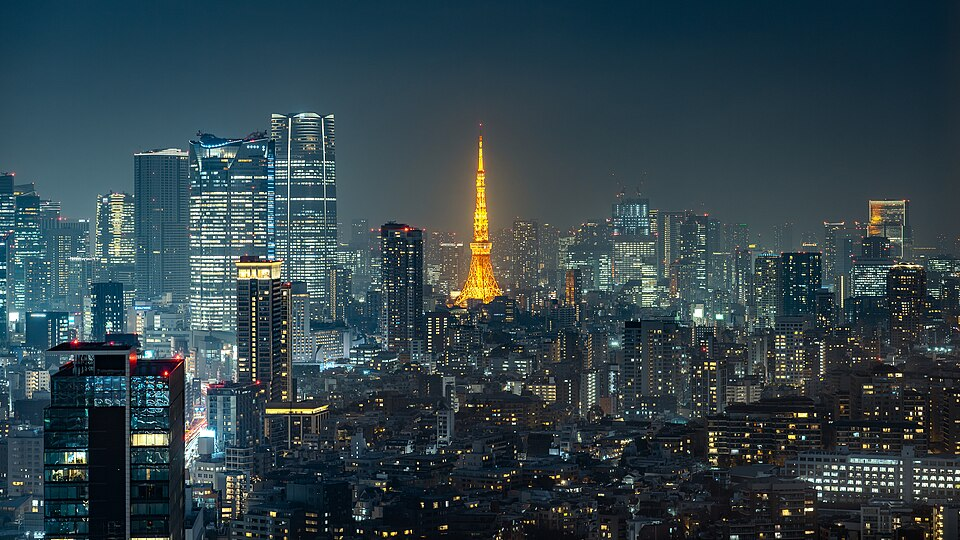

In [29]:
import base64
from IPython.display import Image, display

def find_reference_photo(query: str) -> str:
    """Real tool. Searches Wikimedia Commons for a photo matching `query` and returns
    it as a data URI the model can read directly. Wikimedia's API asks for a
    descriptive User-Agent on requests, so we set one."""
    headers = {"User-Agent": "anatomy-of-ai-agent/1.0 (workshop demo)"}

    def _get(url):
        req = urllib.request.Request(url, headers=headers)
        return urllib.request.urlopen(req, timeout=10)

    search_url = "https://commons.wikimedia.org/w/api.php?" + urllib.parse.urlencode(
        {"action": "query", "format": "json", "list": "search",
         "srsearch": query, "srnamespace": 6, "srlimit": 1}
    )
    with _get(search_url) as r:
        search_result = json.loads(r.read())
    title = search_result["query"]["search"][0]["title"]

    info_url = "https://commons.wikimedia.org/w/api.php?" + urllib.parse.urlencode(
        {"action": "query", "format": "json", "titles": title,
         "prop": "imageinfo", "iiprop": "url", "iiurlwidth": 512}
    )
    with _get(info_url) as r:
        info_result = json.loads(r.read())
    page = next(iter(info_result["query"]["pages"].values()))
    image_url = page["imageinfo"][0]["thumburl"]

    with _get(image_url) as r:
        content_type = r.headers.get_content_type()
        image_bytes = r.read()

    return f"data:{content_type};base64,{base64.b64encode(image_bytes).decode('utf-8')}"


# A real photo of Maya's destination, standing in for a photo she might snap on arrival.
reference_photo = find_reference_photo("Tokyo street scene")
print("Fetched a real photo, encoded as:", reference_photo[:60] + "...")

# Show the actual image, not just the base64 header. This is the "user needs an image
# preview" fix: a harness that hands a model raw base64 and never renders it for the
# human on the other end is hiding information the user actually wants to see.
image_bytes = base64.b64decode(reference_photo.split(",", 1)[1])
display(Image(data=image_bytes, width=400))

In [30]:
# A multimodal message: "content" is a list of parts (text, then image) instead of a
# plain string. This is still one call to the same model, just richer input.
vision_response = client.chat.completions.create(
    model=MODEL,
    messages=[{
        "role": "user",
        "content": [
            {"type": "text", "text": "Describe the weather and conditions visible in this photo in one short sentence."},
            {"type": "image_url", "image_url": {"url": reference_photo}},
        ],
    }],
)
photo_description = vision_response.choices[0].message.content
print(photo_description)

A clear night sky hangs over the brightly lit, sprawling cityscape of Tokyo.


In [31]:
# Feed the model's own description of the photo into the packing sub-agent we already
# built in section 9. No new agent code, just a new source of input for it.
print(packing_subagent.run(photo_description))

# The chain here: a real photo -> a real multimodal model call -> a real sub-agent.
# Swap the search query for whatever a traveler might actually photograph, and this is
# a genuine, working slice of the travel-assistant agent ecosystem this notebook built.

Wear comfortable walking shoes to explore the city streets.


## 11. Capstone, solving Maya's Tokyo trip

Every piece so far was built and proven in isolation: a forecast-aware weather tool, a
currency tool, an itinerary skill, a budget skill, a packing sub-agent, an orchestrator,
a real photo. None of that was decorative. Here they all run in one call, against the
actual goal from the intro: Maya needs a day-by-day plan for Tokyo, weather-aware
packing advice, and her budget in yen.

This orchestrator has every tool built in this notebook, and its system prompt is
assembled the same way `skills_agent` and `budget_agent` were in section 8: scan the
request, inject only the skills that match. The only new wiring is handing it all three
tools (`get_weather`, `convert_currency`, `delegate_to_packing_subagent`) at once.

In [32]:
# The real request Maya has been waiting for this whole notebook.
capstone_request = (
    "I'm flying to Tokyo in 3 days for work. Give me a day-by-day itinerary for the trip "
    "accounting for the weather, tell me what to pack, and convert my daily budget of "
    "$600 to Japanese yen."
)

# Reuse orchestrator_tools / orchestrator_available_tools from section 9 as-is: they
# already have get_weather, convert_currency, and delegate_to_packing_subagent wired up.
maya_prompt = build_system_prompt(SYSTEM_PROMPT, capstone_request, SKILLS)
maya_agent = Agent(MODEL, maya_prompt, orchestrator_tools, orchestrator_available_tools, max_turns=8)

print(maya_agent.run(capstone_request))
print()
print("--- full transcript: every section of this notebook, in one run ---")
for m in maya_agent.messages:
    role = m.get("role")
    content = m.get("content")
    print(f"[{role}] {content if content else m.get('tool_calls')}")

1. **Itinerary**
1. Day 1: Explore Tokyo's clear, chilly streets and enjoy outdoor landmarks.
2. Day 2: Visit shrines and gardens while enjoying the mostly clear weather.
3. Day 3: Stick to indoor activities or museums due to predicted rain.

2. **Packing Advice**
Pack warm layers to handle the chilly temperatures and a waterproof jacket for the rain.

3. **Budget**
Your daily budget is 95,187 JPY.

--- full transcript: every section of this notebook, in one run ---
[system] You are a helpful travel assistant with access to tools. Use a tool whenever it would give a more accurate answer than guessing. Keep answers short.

[Skill: trip_itinerary]
When asked for a trip itinerary, format the answer as a numbered list, one line per day, in the form 'Day N: <plan>'. Keep each day to one line.

[Skill: budget_note]
When money is discussed, always state the currency explicitly (e.g. USD) rather than a bare number.
[user] I'm flying to Tokyo in 3 days for work. Give me a day-by-day itinerary f

## Recap

Everything you built in this notebook.

| Term | What you built |
|---|---|
| **Model** | Raw `client.chat.completions.create()` call. Stateless, no loop |
| **Scaffolding** | `SYSTEM_PROMPT`, `tools_schema`, `AVAILABLE_TOOLS`, the `messages` list |
| **Harness** | The `for` loop in `run_harness` / `Agent.run`. Calls, executes, feeds back, stops |
| **Agent** | The `Agent` class, Model plus Harness, working from Scaffolding |
| **Context engineering** | `self.messages` (short-term) vs `long_term_memory.json` (long-term) |
| **Policy** | Same weights, different `system_prompt`, different behavior |
| **Reasoning (Gemma 4)** | `reasoning={"enabled": True / False}`, an API switch for the model's thinking token. Scaffolding, not a weights change |
| **Tool use / harness engineering** | `convert_currency`'s uncaught `HTTPError`, fed back to the model by the harness |
| **Skills** | `SKILLS` dict, loaded two ways: a keyword router, then a `load_skill` tool the model calls itself |
| **Sub-agents** | `packing_subagent`, a full independent `Agent` exposed to another agent as a tool |
| **Orchestrator** | The outer `Agent` calling `delegate_to_packing_subagent` |
| **Multimodal input** | `vision_response`, a text-plus-image message to the same model, rendered inline |
| **Capstone** | `maya_agent`, every tool + both skills + the sub-agent, solving the actual trip |

Each change along the way had a reason. `get_weather` grew a real forecast because a
single-day reading couldn't answer a multi-day question. `convert_currency` exists because
Maya's budget has to be in yen, and `budget_note` tells the model how to phrase it. Every tool and skill earned its place by being
the thing Maya's assistant actually needed.

### Where to go from here

Every one of these ideas exists in frameworks like **CrewAI**, **LangGraph**, and
**Microsoft Agent Framework** (the successor to AutoGen, which is now in maintenance mode), just with more configuration, more built-in guardrails, streaming,
observability, and production concerns handled for you. Now that you've hand-built the
mechanism, reading *their* source or docs should feel a lot less like magic and a lot
more like "oh, that's just scaffolding" or "that's their harness's stop condition."

Good next steps.
- Rebuild one exercise from this notebook using **CrewAI** or **LangGraph** and diff the
  code against what you wrote here.
- Set `MODEL` to `google/gemma-4-31b-it:free` (or a paid, larger OpenRouter model) and see how much more reliable tool selection and reasoning
  quality get as the model scales up.
- Add a new tool your own trip would actually need (flight status, hotel search, a
  packing checklist that persists to long-term memory) and watch it slot into the same
  scaffolding + harness pattern.